
Loading from: /media/alan/JARVIS/TRANSCORBE/ACF_CCF_12_HHZ_new_2
  TR02 → 165.08 km  (662 days)
  TR03 → 160.20 km  (613 days)
  TR04 → 156.59 km  (662 days)
  TR05 → 153.11 km  (664 days)
  TR08 → 140.56 km  (607 days)
  TR10 → 136.01 km  (606 days)
  TR11 → 131.48 km  (665 days)
  TR12 → 128.89 km  (657 days)
  TR13 → 125.49 km  (657 days)
  TR14 → 120.62 km  (657 days)
  TR15 → 116.83 km  (652 days)
  TR16 → 108.97 km  (658 days)
  TR17 → 106.58 km  (659 days)
  TR18 → 103.63 km  (674 days)
  TR19 → 99.80 km  (674 days)
  TR20 → 95.94 km  (671 days)
  TR21 → 92.48 km  (563 days)
  TR22 → 87.26 km  (638 days)
  TR23 → 84.51 km  (500 days)
  TR24 → 81.78 km  (640 days)
  TR25 → 77.85 km  (672 days)
  TR26 → 75.88 km  (673 days)
  TR27 → 70.88 km  (608 days)
  TR27A → 66.62 km  (29 days)
  TR28 → 68.77 km  (609 days)
  TR28A → 65.98 km  (63 days)
  TR29 → 65.98 km  (608 days)
  TR29A → 65.84 km  (28 days)
  TR30 → 62.19 km  (593 days)
  TR31 → 59.36 km  (652 days)
  TR32 → 55.20 km  (

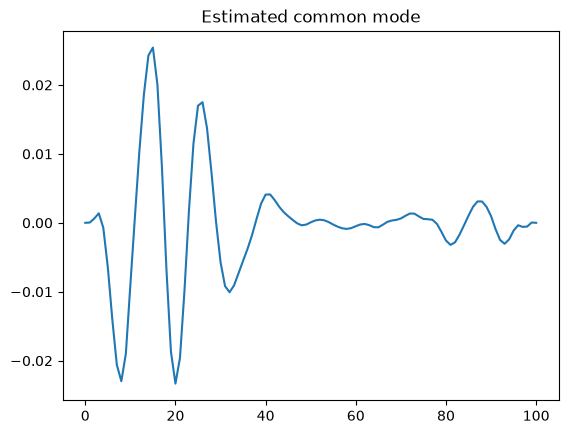


41 stations loaded.

Loading digitized horizons...
  UC: 47 pts, x=16.9-97.3
  LC: 48 pts, x=14.0-100.3
  Alboran: 30 pts, x=113.9-175.0
  Iberian: 48 pts, x=0.3-98.7
Computing PWS horizon picks...
PWS picks (TWT)  : [12.27 12.13 13.33 12.93 13.6  12.93 12.8  11.8  12.   12.33 12.93 12.33
 12.07 11.6  11.07 11.07 11.07 11.53 11.8  13.27 13.07 13.07 11.67 11.6
 12.2  12.8  12.87 12.27 12.33 13.73 14.33 14.33 13.33 13.2  13.2  13.33
 12.8  12.27 11.73 11.87 11.93]
PWS picks (depth): [41.76 41.21 46.13 44.49 47.22 44.49 43.94 39.84 40.66 42.03 44.49 42.03
 40.94 39.02 36.84 36.84 36.84 38.75 39.84 45.86 45.04 45.04 39.3  39.02
 41.48 43.94 44.22 41.76 42.03 47.77 50.23 50.23 46.13 45.58 45.58 46.13
 43.94 41.76 39.57 40.12 40.39]


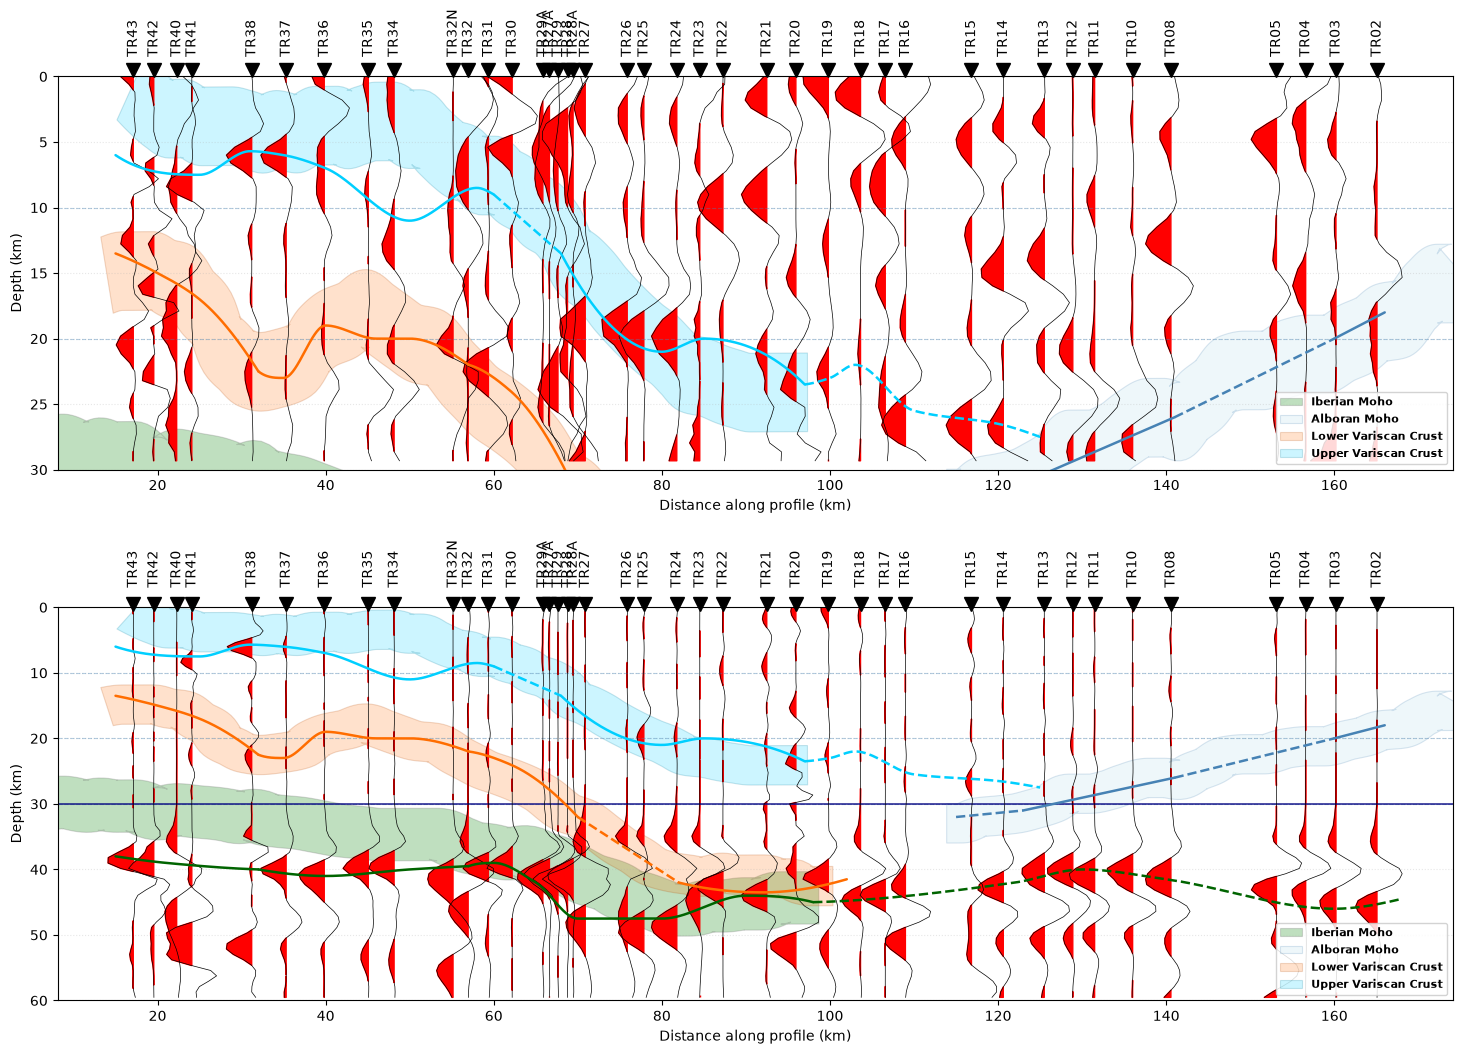

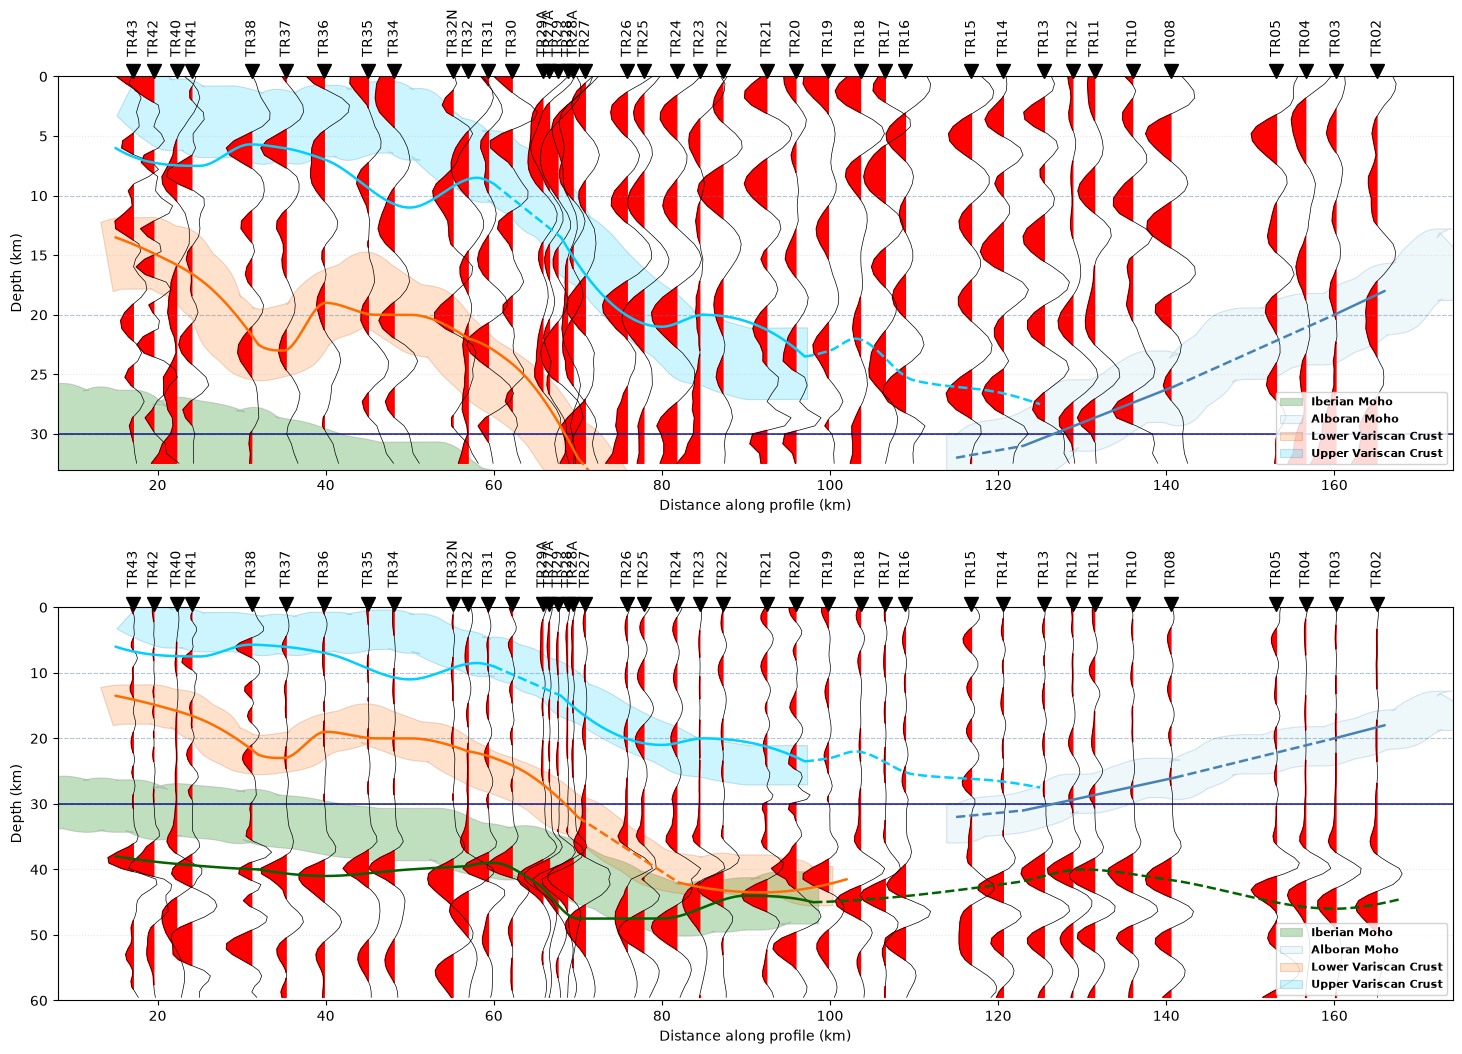

In [ ]:
""" csv moho ! overlay new
FULL TWT → DEPTH SECTION  —  standalone, folder-driven
+ Digitized geological horizon overlay from WPD CSV
+ PWS peak-tracked Iberian Moho line (LS panels)
+ Manual solid/dashed segment lines for LC, UC, Alboran (LS panels)
"""

import numpy as np
import scipy.signal as signal
from scipy.signal import savgol_filter, hilbert
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import glob, os, pandas as pd
from scipy.ndimage import uniform_filter1d
from obspy.geodetics import gps2dist_azimuth
from obspy import read_inventory

# ═══════════════════════════════════════════════════════════════
#  USER CONFIG
# ═══════════════════════════════════════════════════════════════
ACF_ROOT   = r"/media/alan/JARVIS/TRANSCORBE/ACF_CCF_12_HHZ_new_2"
STATIONXML = r"/media/alan/JARVIS/TRANSCORBE/TRANSCORBE.xml"

HORIZONS_CSV = r"/media/alan/JARVIS/TRANSCORBE/horizons.csv"

TARGET_DT   = 0.2
MAXLAG      = 20
PERIOD_MIN  = 1
PERIOD_MAX  = 6

PROFILE_START = (38.33, -3.08)
PROFILE_END   = (37.43, -1.08)

CRUST_LAYERS = [
    (10.0, 6.0),
    (10.0, 6.4),
    (10.0, 6.8),
]
V_MANTLE = 8.2

SCALE      = 3
# ═══════════════════════════════════════════════════════════════


# ── helpers ─────────────────────────────────────────────────────
_, PROFILE_AZ, _ = gps2dist_azimuth(
    PROFILE_START[0], PROFILE_START[1],
    PROFILE_END[0],   PROFILE_END[1])

def projected_dist(station_coords, station):
    lat, lon = station_coords[station]
    dist, az, _ = gps2dist_azimuth(
        PROFILE_START[0], PROFILE_START[1], lat, lon)
    return dist * np.cos(np.deg2rad(az - PROFILE_AZ)) / 1000.0

def cosine_taper(n, pct=0.05):
    m = int(pct * n)
    w = np.ones(n)
    taper = np.sin(np.linspace(0, np.pi/2, m))**2
    w[:m] = taper; w[-m:] = taper[::-1]
    return w

def zero_lag_taper(acf, dt, mute_sec=3):
    """Causal version: mute only lags 0 → mute_sec."""
    n = len(acf)
    mute_samples = int(round(mute_sec / dt))
    if mute_samples < 1:
        return acf.copy()
    if mute_samples >= n:
        return np.zeros_like(acf)
    window = np.ones(n)
    window[:mute_samples] = np.sin(np.linspace(0.0, np.pi/2, mute_samples))**2
    return acf * window

def bandpass(acf, dt, fmin_period, fmax_period, order=4):
    fs  = 1.0 / dt; nyq = fs / 2.0
    flo = 1.0 / fmax_period
    fhi = 1.0 / fmin_period
    if fhi >= nyq: raise ValueError("fhi >= Nyquist")
    sos = signal.butter(order, [flo, fhi], btype='band', fs=fs, output='sos')
    return signal.sosfiltfilt(sos, acf)

def remove_trend(acf):
    window = int(4 / TARGET_DT)          # int(2/0.2) = 10
    if window % 2 == 0:
        window += 1                      # → 11
    trend = savgol_filter(acf, window, 2)
    return acf - trend

def phase_shift(acf, dt):
    n = len(acf)
    freqs = np.fft.fftfreq(n, d=dt)
    F = np.fft.fft(acf)
    ps = np.where(freqs > 0, np.exp(-1j*np.pi/2),
        np.where(freqs < 0, np.exp(1j*np.pi/2), 1.0))
    return np.real(np.fft.ifft(F * ps))

def pws(data):
    analytic  = hilbert(data, axis=1)
    phase     = analytic / np.abs(analytic + 1e-10)
    coherence = np.abs(np.mean(phase, axis=0))**2
    return np.mean(data, axis=0) * coherence

def twt_to_depth(t_twt, layers=CRUST_LAYERS, v_man=V_MANTLE):
    t1 = t_twt / 2.0; depth = 0.0
    for h, v in layers:
        dt = h / v
        if t1 <= dt: return depth + t1 * v
        t1 -= dt; depth += h
    return depth + t1 * v_man

def build_depth_axis(lags):
    return np.array([twt_to_depth(t) for t in lags])


# ── PWS peak-tracked horizon ─────────────────────────────────────
HORIZON_WINDOW_TWT = (9.0, 16.0)   # TWT seconds — edit window here

def compute_pws_horizon(section, distances, target_dt=TARGET_DT,
                        maxlag=MAXLAG, window=HORIZON_WINDOW_TWT,
                        smooth_window=3):
    t0, t1 = window
    sec = np.roll(section, -section.shape[1] // 2, axis=1)
    n = sec.shape[1]
    lags = np.arange(n) * target_dt
    mask = lags <= maxlag
    time_plot = lags[mask]
    pick_mask = (time_plot >= t0) & (time_plot <= t1)
    ht = []
    for i in range(len(distances)):
        tr = sec[i][mask].copy()
        tr_norm = tr / (np.max(np.abs(tr)) + 1e-10)
        window_trace = tr_norm[pick_mask]
        pos = np.where(window_trace > 0, window_trace, 0)
        idx = np.argmax(pos) if pos.max() > 0 else np.argmax(np.abs(window_trace))
        ht.append(time_plot[pick_mask][idx])
    ht = np.array(ht)
    q1, q3 = np.percentile(ht, [25, 75])
    iqr = q3 - q1
    ht = np.clip(ht, q1 - 1.5*iqr, q3 + 1.5*iqr)
    return uniform_filter1d(ht, size=smooth_window, mode='nearest')


import csv

def load_horizons(csv_path):
    df = pd.read_csv(csv_path)
    df.columns = ['horizon', 'distance_km', 'depth_km']
    df[['distance_km', 'depth_km']] = df[['distance_km', 'depth_km']].apply(pd.to_numeric, errors='coerce')
    df = df.dropna()
    out = {}
    for name, g in df.groupby('horizon', sort=False):
        g = (g.sort_values('distance_km')
              .groupby('distance_km', as_index=False)['depth_km'].mean())  # Pchip needs unique x
        out[name.strip()] = (g.distance_km.values, g.depth_km.values)
        print(f"  {name}: {len(g)} pts, x={g.distance_km.min():.1f}-{g.distance_km.max():.1f}")
    return out


# ── load & process ───────────────────────────────────────────────
print(f"\nLoading from: {ACF_ROOT}")
inventory = read_inventory(STATIONXML)
station_coords = {sta.code: (sta.latitude, sta.longitude)
                for net in inventory for sta in net}

station_dirs = sorted(glob.glob(os.path.join(ACF_ROOT, "*")))
section_linear, section_pws_list = [], []
distances, station_names, day_counts = [], [], []

for sd in station_dirs:
    sta = os.path.basename(sd)
    if sta not in station_coords:
        print(f"  skip {sta} (not in xml)"); continue
    files = sorted(glob.glob(os.path.join(sd, "*.npy")))
    if not files: continue
    traces = []
    for f in files:
        acf = np.load(f)
        acf = bandpass(acf, TARGET_DT, PERIOD_MIN, PERIOD_MAX)
        acf = remove_trend(acf)                           # SavGol detrend
        acf = zero_lag_taper(acf, TARGET_DT, mute_sec=3)  # zero-lag mute (0–3 s)
        acf *= cosine_taper(len(acf))                     # edge taper
        traces.append(acf)
    traces = np.vstack(traces)
    section_linear.append(np.mean(traces, axis=0))
    section_pws_list.append(traces)
    day_counts.append(traces.shape[0])
    d = projected_dist(station_coords, sta)
    distances.append(d); station_names.append(sta)
    print(f"  {sta} → {d:.2f} km  ({traces.shape[0]} days)")

section_linear   = np.array(section_linear)
distances        = np.array(distances)
day_counts       = np.array(day_counts)
order            = np.argsort(distances)
section_linear   = section_linear[order]
section_pws_list = [section_pws_list[i] for i in order]
distances        = distances[order]
station_names    = np.array(station_names)[order]
day_counts       = day_counts[order]

common_mode_linear = np.average(section_linear, axis=0, weights=day_counts)
plt.plot(common_mode_linear)
plt.title("Estimated common mode")
plt.show()
#section_linear = section_linear - common_mode_linear[np.newaxis, :]
section_linear = np.array([phase_shift(tr, TARGET_DT) for tr in section_linear])

section_pws_arr = np.array([
    pws(np.array([phase_shift(tr, TARGET_DT) for tr in traces]))
    for traces in section_pws_list])
#section_pws_arr = section_pws_arr - common_mode_linear[np.newaxis, :]

print(f"\n{section_linear.shape[0]} stations loaded.")

print("\nLoading digitized horizons...")
H = load_horizons(HORIZONS_CSV)
horizons = []   # old arg, now unused

# ── compute PWS picks → depth (used in LS panels) ────────────────
print("Computing PWS horizon picks...")
pws_horizon_twt   = compute_pws_horizon(section_pws_arr, distances)
pws_horizon_depth = np.array([twt_to_depth(t) for t in pws_horizon_twt])
print("PWS picks (TWT)  :", np.round(pws_horizon_twt, 2))
print("PWS picks (depth):", np.round(pws_horizon_depth, 2))


# ═══════════════════════════════════════════════════════════════
#  RIBBON CONTROL POINTS  — edit here
# ═══════════════════════════════════════════════════════════════
from scipy.interpolate import PchipInterpolator

IB_CTRL_X, IB_CTRL_Y = H['Iberian']
AL_CTRL_X, AL_CTRL_Y = H['Alboran']
LC_CTRL_X, LC_CTRL_Y = H['LC']
UC_CTRL_X, UC_CTRL_Y = H['UC']

IB_WIDTH   = 4.0
IB_COLOR   = 'green'
AL_WIDTH   = 3.0
AL_COLOR   = 'lightblue'
AL_EDGE    = 'steelblue'
LC_WIDTH   = 3
LC_COLOR   = '#ff6d00'
LC_EDGE    = '#b34700'
UC_WIDTH   = 3
UC_COLOR   = '#00cfff'
UC_EDGE    = '#007a99'

UC_LINE = [
    (np.array([15, 25, 31, 35, 40, 50, 58, 60]),          np.array([6, 7.5, 5.7, 6, 7, 11, 8.5, 9]),      '-' ),   # strong
    (np.array([60, 68]),      np.array([9, 13.5]),    '--' ),   # weak
    (np.array([68, 80, 85, 97]),          np.array([13.5, 21, 20, 23.5]),      '-' ),   # strong
    (np.array([97, 100, 103, 110, 120, 125]),      np.array([23.5, 23, 22, 25.5, 26.5, 27.5]),    '--' ),   # weak
]

LC_LINE = [
    (np.array([15, 20, 25, 32]),          np.array([ 13.5, 15, 17, 22.5]),        '-'),   # strong
    (np.array([32, 35, 40, 46, 50, 57]),      np.array([22.5, 23, 19, 20, 20, 22]),    '-' ),   # weak
    (np.array([57,62, 70]),          np.array([22,24, 32]),        '-' ),   # strong
    (np.array([70, 82]),      np.array([32, 42]),    '--' ),   # weak
    (np.array([82, 92, 102]),          np.array([42, 43.5, 41.5]),        '-' ),   # strong
]

ALB_LINE = [
    (np.array([115, 123]),  np.array([32, 31]),  '--'),   # weak 
    (np.array([123, 141]),       np.array([31, 26]),       '-' ),   # strong
    (np.array([141, 160]),            np.array([26, 20]),            '--'),   # weak 
    (np.array([160, 166]),       np.array([20, 18]),       '-' ),   # strong
]

IB_LINE = [
    (np.array([15, 21, 32]),      np.array([38, 39, 40]), '-'),
    (np.array([32, 40, 50, 57]),      np.array([40, 41, 40, 39.5]),     '-'),
    (np.array([57, 60, 65, 70, 80, 90, 98]),         np.array([39.5, 39, 42, 47.5, 47.5, 44, 45]),             '-'),
    (np.array([98, 122, 130, 140, 160, 168]),          np.array([45, 42, 40, 41.5, 46, 44.5]),    '--'),  # weak
]

# line colors
ALB_LINE_COLOR = 'steelblue'
LC_LINE_COLOR  = '#ff6d00'
UC_LINE_COLOR  = '#00cfff'
IB_LINE_COLOR  = 'darkgreen'
LINE_LW        = 1.8
# ═══════════════════════════════════════════════════════════════

def draw_ribbon(ax, ctrl_x, ctrl_y, width,facecolor, edgecolor='goldenrod',alpha=0.30, label=None):
    xnew = np.linspace(ctrl_x.min(), ctrl_x.max(), 500)
    ynew = PchipInterpolator(ctrl_x, ctrl_y)(xnew)
    dx = np.gradient(xnew)
    dy = np.gradient(ynew)
    nlen = np.sqrt(dx**2 + dy**2)
    nx = -dy / nlen
    ny =  dx / nlen
    half = width 
    x1 = xnew + half * nx
    y1 = ynew + half * ny
    x2 = xnew - half * nx
    y2 = ynew - half * ny
    px = np.concatenate([x1, x2[::-1]])
    py = np.concatenate([y1, y2[::-1]])
    from matplotlib.patches import Polygon
    patch = Polygon(np.column_stack((px, py)),closed=True,facecolor=facecolor,
        edgecolor=edgecolor,linewidth=0.8,alpha=alpha,joinstyle='round',zorder=0,label=label)
    ax.add_patch(patch)

def draw_manual_line(ax, segments, color, lw=LINE_LW, label=None):
    """Draw horizon as ordered solid/dashed segments.
    Label applied to first segment only."""
    for k, (xs, ys, ls) in enumerate(segments):
        xnew = np.linspace(xs.min(), xs.max(), 300)
        ynew = PchipInterpolator(xs, ys)(xnew)
        ax.plot(xnew,ynew,color=color,lw=lw,linestyle=ls,zorder=7,solid_capstyle='round')

def make_plot_distances(distances, scale):
    pd = distances.copy().astype(float)
    for i in range(1, len(pd)):
        if abs(pd[i] - pd[i-1]) < scale * 0.6:
            pd[i] = pd[i-1] + scale * 0.6
    return pd


def plot_stack_figure(section, stack_label, distances, station_names,component, horizons, pws_horizon_depth=None):
    legend_font = fm.FontProperties(size=8, weight='bold')
    if stack_label == 'PWS':
        configs = [(0, 30), (0, 60)]
    else:
        configs = [(0, 33), (0, 60)]
    fig, axes = plt.subplots(2, 1, figsize=(18, 12), gridspec_kw={'hspace': 0.35})
    for ax, (depth_min, depth_max) in zip(axes, configs):
        sec = np.roll(section, -section.shape[1]//2, axis=1)
        n   = sec.shape[1]
        lags     = np.arange(n) * TARGET_DT
        lag_mask = lags <= MAXLAG
        lags_use = lags[lag_mask]
        depths   = build_depth_axis(lags_use)
        d_mask   = (depths >= depth_min) & (depths <= depth_max)
        depths_w = depths[d_mask]
        plot_dists = make_plot_distances(distances, SCALE)
        for i in range(sec.shape[0]):
            tr   = sec[i][lag_mask][d_mask].copy()
            mx   = np.max(np.abs(tr)) + 1e-10
            tr_n = tr / mx
            x    = plot_dists[i] + tr_n * SCALE
            ax.plot(x, depths_w, color='black', linewidth=0.5, zorder=3)
            ax.fill_betweenx(depths_w, plot_dists[i], x,where=(tr_n > 0), color='none', interpolate=True, zorder=2)
            ax.fill_betweenx(depths_w, plot_dists[i], x,where=(tr_n < 0), color='red', interpolate=True, zorder=2)
            ax.text(plot_dists[i], 1.05, station_names[i], fontsize=10, rotation=90,ha='center', va='bottom', fontfamily='DejaVu Sans',transform=ax.get_xaxis_transform(), clip_on=False)
            ax.plot(plot_dists[i], -0.5, marker='v', color='black',markersize=10, clip_on=False, zorder=5)

        # layer boundary dashes
        cum = 0.0
        for h, v in CRUST_LAYERS:
            cum += h
            if depth_min < cum < depth_max:
                ax.axhline(cum, color='steelblue', lw=0.8, ls='--', alpha=0.4)
        moho = sum(h for h, _ in CRUST_LAYERS)
        if depth_min < moho < depth_max:
            ax.axhline(moho, color='navy', lw=1.4, ls='-', alpha=0.7)

        # ── PWS: ribbons only ────────────────────────────────────
        if stack_label == 'PWS':
            draw_ribbon(ax, IB_CTRL_X, IB_CTRL_Y, IB_WIDTH,IB_COLOR, edgecolor='dimgray', alpha=0.25, label='Iberian Moho')
            draw_ribbon(ax, AL_CTRL_X, AL_CTRL_Y, AL_WIDTH,AL_COLOR, edgecolor=AL_EDGE, alpha=0.20, label='Alboran Moho')
            draw_ribbon(ax, LC_CTRL_X, LC_CTRL_Y, LC_WIDTH,LC_COLOR, edgecolor=LC_EDGE, alpha=0.20, label='Lower Variscan Crust')
            draw_ribbon(ax, UC_CTRL_X, UC_CTRL_Y, UC_WIDTH,UC_COLOR, edgecolor=UC_EDGE, alpha=0.20, label='Upper Variscan Crust')

            draw_manual_line(ax, IB_LINE, IB_LINE_COLOR, label='Iberian Moho')
            draw_manual_line(ax, ALB_LINE, ALB_LINE_COLOR, label='Alboran Moho')
            draw_manual_line(ax, LC_LINE,  LC_LINE_COLOR,  label='LC boundary')
            draw_manual_line(ax, UC_LINE,  UC_LINE_COLOR,  label='UC boundary')

        # ── LS: ribbons + PWS peak line + manual segment lines ───
        elif stack_label == 'LS':
            # ribbons (lower alpha — lines sit on top)
            draw_ribbon(ax, IB_CTRL_X, IB_CTRL_Y, IB_WIDTH,IB_COLOR, edgecolor='dimgray', alpha=0.25, label='Iberian Moho')
            draw_ribbon(ax, AL_CTRL_X, AL_CTRL_Y, AL_WIDTH,AL_COLOR, edgecolor=AL_EDGE, alpha=0.20, label='Alboran Moho')
            draw_ribbon(ax, LC_CTRL_X, LC_CTRL_Y, LC_WIDTH,LC_COLOR, edgecolor=LC_EDGE, alpha=0.20, label='Lower Variscan Crust')
            draw_ribbon(ax, UC_CTRL_X, UC_CTRL_Y, UC_WIDTH,UC_COLOR, edgecolor=UC_EDGE, alpha=0.20, label='Upper Variscan Crust')

            draw_manual_line(ax, IB_LINE, IB_LINE_COLOR, label='Iberian Moho')
            draw_manual_line(ax, ALB_LINE, ALB_LINE_COLOR, label='Alboran Moho')
            draw_manual_line(ax, LC_LINE,  LC_LINE_COLOR,  label='LC boundary')
            draw_manual_line(ax, UC_LINE,  UC_LINE_COLOR,  label='UC boundary')

        ax.set_ylim(depth_min, depth_max)
        ax.invert_yaxis()
        ax.set_xlabel("Distance along profile (km)", fontsize=10)
        ax.set_ylabel("Depth (km)", fontsize=10)
        ax.legend(loc='lower right', prop=legend_font, framealpha=0.85)
        ax.grid(axis='y', ls=':', alpha=0.3)
        ax.set_xlim(plot_dists[0] - SCALE * 3, plot_dists[-1] + SCALE * 3)

    plt.show()


# ── run ───────────────────────────────────────────────────────────
component = os.path.basename(ACF_ROOT)
plot_stack_figure(section_pws_arr, "PWS", distances, station_names, component, horizons)
plot_stack_figure(section_linear,  "LS",  distances, station_names, component, horizons,pws_horizon_depth=pws_horizon_depth)